# ДЗ №0. Готовность к курсу Deep Learning

**Дедлайн: воскресенье, 22 ноября 2026 года.** Время сдачи уточняется преподавателем.

Цель — проверить, что вы разобрали три пособия нулевой недели и можете применить
основные идеи на небольших новых примерах. Здесь не нужно обучать большую нейросеть
или добиваться рекордной метрики. Работа рассчитана примерно на 2–3 часа после пособий;
это ориентир, а не ограничение времени.

**Можно пользоваться пособиями и документацией.** Если вы использовали помощь человека
или ИИ, кратко укажите её в конце. Вы должны уметь объяснить своё решение и результат.
Правильный код без объяснения не подтверждает понимание всей темы.

| Блок | Задания | Баллы |
| --- | --- | ---: |
| NumPy: формы, память и вычисления | 1–4 | 34 |
| Математика, градиент и обучение | 5–8 | 34 |
| Честный ML-эксперимент | 9–12 | 32 |
| Всего | 12 заданий | 100 |

Рекомендуемый критерий готовности: не менее **70/100**, при этом не менее половины
баллов каждого блока. Окончательное решение и необходимость доработки определяет
преподаватель. Автопроверки не выставляют итоговую оценку: письменные ответы и качество
реализации оцениваются отдельно.

## Как работать и что сдавать

1. Сохраните свою копию как `HW0_Фамилия_Имя.ipynb` и заполните сведения ниже.
2. В ячейках с решениями замените `None` рабочим кодом. Сохраните имена и сигнатуры.
3. В каждом задании заполните поле «Ваше объяснение»: обычно достаточно 2–4 предложений.
4. Ячейки данных и самопроверки не изменяйте. Успех проверки не заменяет ответ на вопрос.
5. Перед отправкой выполните **Restart Kernel → Run All**, сохраните выводы и сам файл.
6. Отправьте один `.ipynb`. Не отправляйте скриншоты вместо ноутбука.

Шаблон можно запустить целиком до решения: незаполненные задания покажут «Не выполнено».
Это ожидаемое поведение, а не ошибка окружения. Если изменить решение, перезапустите
соответствующую самопроверку; финальный отчёт иначе может показывать старый результат.

Требования к коду: без лишних `print`, эмодзи и длинных комментариев. Объяснения пишите
в Markdown. Используйте окружение из [README подготовительных пособий](../README.md).
Данные встроены; CPU достаточно, интернет для вычислений не нужен.

**Имя и фамилия:** _заполните_.  
**Какие пособия прочитаны:** _заполните_.

In [1]:
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from IPython.display import display
from sklearn.base import clone
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix

COLORS = ["#2455A4", "#E58A2B", "#168C83"]
plt.rcParams.update({
    "figure.figsize": (9, 4), "figure.dpi": 115, "font.family": "DejaVu Sans",
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.facecolor": "#F5F7FB", "axes.grid": True, "grid.alpha": 0.2,
    "axes.axisbelow": True, "figure.constrained_layout.use": True
})
pd.set_option("display.precision", 5)
pd.set_option("display.max_colwidth", None)
checks = {}

def pending(value):
    if value is None:
        return True
    if isinstance(value, dict):
        return any(pending(item) for item in value.values())
    if isinstance(value, (tuple, list)):
        return any(pending(item) for item in value)
    return False

def verify(number, operation, validator):
    try:
        value = operation()
        if pending(value):
            status, detail = "Не выполнено", "Замените None своим решением"
        else:
            validator(value)
            status, detail = "Проверки пройдены", "Письменное объяснение оценивается отдельно"
    except Exception as error:
        status, detail = "Нужно исправить", f"{type(error).__name__}: {error}"
    checks[number] = {"Задание": number, "Статус": status, "Примечание": detail}
    return pd.DataFrame([checks[number]]).set_index("Задание")

pd.DataFrame({"Компонент": ["Python", "NumPy", "scikit-learn", "PyTorch"],
              "Версия": [platform.python_version(), np.__version__, sklearn.__version__, torch.__version__]})

,Компонент,Версия
0,Python,3.12.10
1,NumPy,2.5.5
2,scikit-learn,1.9.1
3,PyTorch,2.15.0+cpu


## Данные для блока A: NumPy

Строка соответствует объекту, столбец — признаку. Последний столбец намеренно
константный. `A_new` — новые наблюдения: по ним нельзя пересчитывать статистики обучения.
Разные масштабы признаков сделаны специально.

Материалы: [пособие 1](../01_python_numpy.ipynb), разделы 4–12 и 19–22.
Все исходные массивы в этой ячейке должны оставаться неизменными после ваших вычислений.

In [2]:
A_train = np.array([[1., 10., 5.], [2., 20., 5.], [3., 30., 5.], [4., 40., 5.]])
A_new = np.array([[5., 50., 5.], [0., 0., 5.]])
A_train_snapshot, A_new_snapshot = A_train.copy(), A_new.copy()
pd.DataFrame(A_train, columns=["Признак 1", "Признак 2", "Константа"])

,Признак 1,Признак 2,Константа
0,1.0,10.0,5.0
1,2.0,20.0,5.0
2,3.0,30.0,5.0
3,4.0,40.0,5.0


## 1. Формы массивов — 6 баллов

Запишите формы четырёх выражений как кортежи, сначала предсказав их без исполнения:
`A_train[:, 0]`, `A_train[:, :1]`, `A_train.mean(axis=0, keepdims=True)` и
`A_train.T @ A_train`. В словаре ниже используются ключи `vector`, `column`, `mean`, `gram`.

**Объясните:** почему первые два выражения имеют разное число осей и почему транспонирование
одномерного массива не превращает его в столбец? Ссылка: пособие 1, разделы 4–6 и 18.

**Ваше объяснение:** _NumPy убирает ось, по которой индекс зафиксирован, а срез сохраняет ось. У одномерного массива всего одна ось._

In [3]:
shapes = {"vector": (4,), "column": (4, 1), "mean": (1, 3), "gram": (3, 3)}


### Самопроверка задания 1

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

In [4]:
def check_shapes(value):
    expected = {"vector": A_train[:, 0].shape, "column": A_train[:, :1].shape,
                "mean": A_train.mean(axis=0, keepdims=True).shape,
                "gram": (A_train.T @ A_train).shape}
    assert set(value) == set(expected), "Сохраните четыре заданных ключа"
    assert all(isinstance(v, tuple) for v in value.values()), "Формы запишите кортежами"
    assert value == expected, "Проверьте, какие оси сохраняются в каждом выражении"

verify(1, lambda: shapes, check_shapes)

,Статус,Примечание
Задание,,
1,Проверки пройдены,Письменное объяснение оценивается отдельно


## 2. Тихая ошибка broadcasting — 8 баллов

Факт имеет форму `(n, 1)`, а прогноз — `(n,)`. Выражение `np.mean((actual - predicted)**2)`
исполняется, но сравнивает не те пары. Напишите `paired_mse`, которая принимает факты
формы `(n,)` или `(n, 1)` и прогноз формы `(n,)`, возвращает MSE соответствующих объектов
и не изменяет входы. Для разных длин входов выбросьте `ValueError`.

$$\operatorname{MSE}=\frac1n\sum_i(y_i-\hat y_i)^2.$$

**Объясните:** какую форму имела неправильная разность и почему итоговое усреднение
маскирует проблему? Ссылка: пособие 1, разделы 8–9 и 16.

**Ваше объяснение:** _После broadcasting форма прогноза стала (n,) -> (1, n) -> (n, n), а форма фактов стала (n, 1) -> (n, n), в итоге неправильная разность имела форму (n, n). Итоговое усреднение маскирует проблему, потому что в итоге выдает одно скалярное число, что мы и ожидаем увидеть на выходе._

In [5]:
def paired_mse(actual, predicted):
    fact = actual.reshape(-1)
    if len(fact) != len(predicted):
        raise ValueError
    return np.sum((fact - predicted) ** 2) / len(predicted)

### Самопроверка задания 2

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

In [6]:
def check_mse(value):
    np.testing.assert_allclose(value, 0.02, atol=1e-12)
    np.testing.assert_allclose(paired_mse(np.array([2., 4.]), np.array([1., 6.])), 2.5)
    original = np.array([[1.], [2.], [3.]])
    before = original.copy()
    paired_mse(original, np.array([1.1, 1.9, 3.2]))
    np.testing.assert_array_equal(original, before)
    try:
        paired_mse(np.array([1., 2.]), np.array([1., 2., 3.]))
    except ValueError:
        pass
    else:
        raise AssertionError("Разные длины должны приводить к ValueError")

verify(2, lambda: paired_mse(np.array([[1.], [2.], [3.]]), np.array([1.1, 1.9, 3.2])), check_mse)

,Статус,Примечание
Задание,,
2,Проверки пройдены,Письменное объяснение оценивается отдельно


## 3. Стандартизация без изменения исходника — 10 баллов

Напишите функцию, которая вычисляет среднее и стандартное отклонение **только по train**,
заменяет нулевой масштаб единицей и возвращает `(train_z, new_z, mean, scale)`.
Используйте `ddof=0`. Формы `mean` и `scale` должны быть `(1, d)`. Входы не изменяйте.

$$z_j=(x_j-\mu_j)/s_j.$$

**Объясните:** что получится в константном столбце и почему нельзя отдельно стандартизировать
`A_new` по его собственным статистикам? Укажите, как избежали изменения общего буфера.
Ссылка: пособие 1, разделы 7 и 10–12.

**Ваше объяснение:** _В константном столбце все значения заменятся на 0. Его нельзя стандартизировать по его собственным статистикам, потому что это проитворечит логике машинного обучения: A_new соответствует новым данным, которые модель не видела и которые служат для нас валидационной выборкой. Не изменял значений исходных массивов._

In [7]:
def standardize(train, new):
    n = train.shape[0]
    mean = np.mean(train, axis=0, keepdims=True)
    scale = np.sqrt(np.sum((train - mean) ** 2, axis=0, keepdims=True) / n)
    scale = np.where(scale, scale, 1)
    train_z = (train - mean) / scale
    new_z = (new - mean) / scale
    return train_z, new_z, mean, scale

### Самопроверка задания 3

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

,Статус,Примечание
Задание,,
3,Проверки пройдены,Письменное объяснение оценивается отдельно


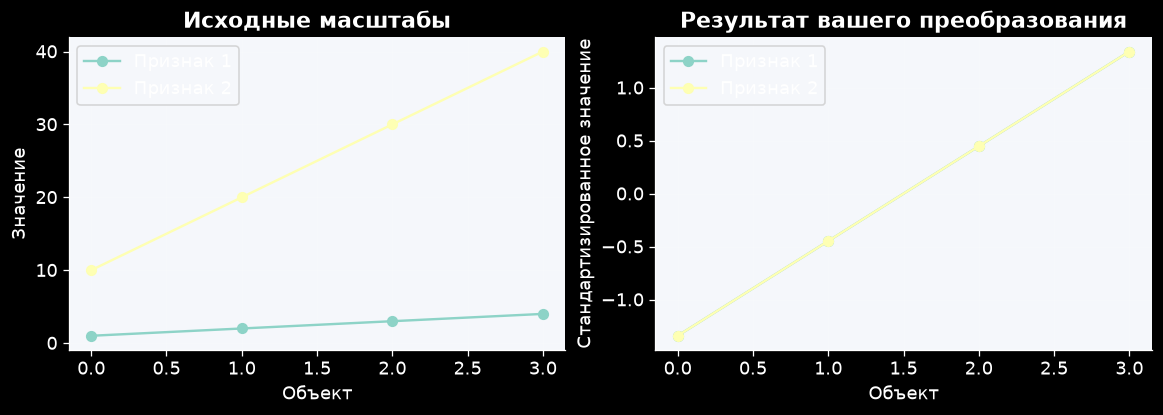

In [8]:
def check_standardization(value):
    train_z, new_z, mean, scale = value
    assert train_z.shape == A_train.shape and new_z.shape == A_new.shape
    assert mean.shape == scale.shape == (1, 3)
    np.testing.assert_allclose(train_z.mean(axis=0), 0, atol=1e-12)
    np.testing.assert_allclose(train_z[:, :2].std(axis=0), 1, atol=1e-12)
    np.testing.assert_allclose(train_z[:, 2], 0, atol=1e-12)
    np.testing.assert_allclose(new_z * scale + mean, A_new, atol=1e-12)
    np.testing.assert_allclose(mean, A_train_snapshot.mean(0, keepdims=True))
    np.testing.assert_allclose(scale, [[np.sqrt(1.25), np.sqrt(125), 1.]])
    np.testing.assert_array_equal(A_train, A_train_snapshot)
    np.testing.assert_array_equal(A_new, A_new_snapshot)
    alternative = standardize(A_train, np.array([[100., 1000., 5.]]))
    np.testing.assert_allclose(alternative[2], mean)
    np.testing.assert_allclose(alternative[3], scale)

display(verify(3, lambda: standardize(A_train, A_new), check_standardization))
if checks[3]["Статус"] == "Проверки пройдены":
    train_z, new_z, _, _ = standardize(A_train, A_new)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for j in range(2):
        axes[0].plot(A_train[:, j], "o-", label=f"Признак {j+1}")
        axes[1].plot(train_z[:, j], "o-", label=f"Признак {j+1}")
    axes[0].set(title="Исходные масштабы", xlabel="Объект", ylabel="Значение")
    axes[1].set(title="Результат вашего преобразования", xlabel="Объект", ylabel="Стандартизированное значение")
    for ax in axes:
        ax.legend()
    plt.show()

## 4. Ближайшие объекты без цикла по строкам — 10 баллов

Реализуйте поиск `k` ближайших строк по евклидову расстоянию. Возвращайте кортеж
`(indices, distances)` из двух одномерных массивов длины `k`, отсортированных по расстоянию.
При равных расстояниях сохраняйте порядок строк базы: используйте стабильную сортировку.
Для `k < 1` или `k > n` выбросьте `ValueError`. Считайте расстояния средствами NumPy,
без Python-цикла по объектам.

База уже находится в нужной системе координат. Дополнительное масштабирование не нужно.
**Объясните:** по какой оси суммируются квадраты и сколько памяти требует временная
разность для одного запроса? Ссылка: пособие 1, разделы 19–24.

**Ваше объяснение:** _Квадраты суммируются по первой оси (горизонтальная). Требуется O(n^2) памяти, если мы учитываем, что нам нужно хранить базу данных, если же это не учитывать, то O(n)_

In [9]:
search_base = np.array([[0., 0.], [1., 0.], [0., 1.], [3., 3.]])
search_query = np.array([0.2, 0.2])

def nearest(database, query, k):
    n = database.shape[0]
    if k > n or k < 1:
        raise ValueError
    distances = np.sqrt(np.sum((database - query) ** 2, axis=1, keepdims=False))
    indices = np.argsort(distances, kind='stable')[:k]
    return (indices, distances[indices])

In [10]:
nearest(search_base, search_query, 2)

(array([0, 1]), array([0.28284271, 0.82462113]))

### Самопроверка задания 4

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

,Статус,Примечание
Задание,,
4,Проверки пройдены,Письменное объяснение оценивается отдельно


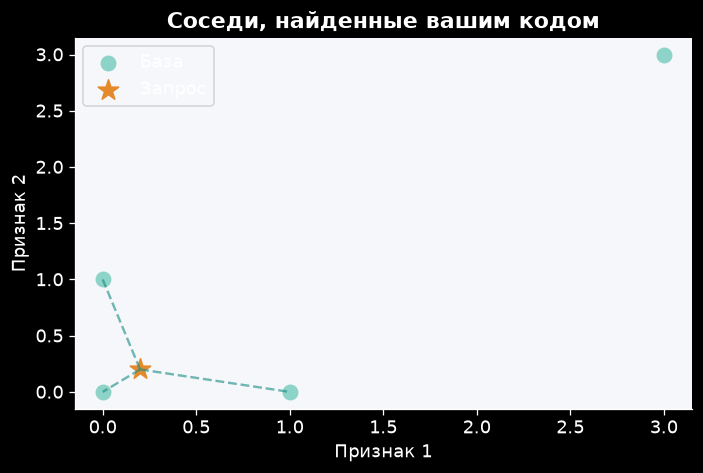

In [11]:
def check_neighbors(value):
    indices, distances = value
    np.testing.assert_array_equal(indices, [0, 1, 2])
    np.testing.assert_allclose(distances, np.sqrt([0.08, 0.68, 0.68]))
    assert indices.shape == distances.shape == (3,)
    single = nearest(search_base, np.array([3., 3.]), 1)
    np.testing.assert_array_equal(single[0], [3])
    np.testing.assert_allclose(single[1], [0])
    assert len(nearest(search_base, search_query, 4)[0]) == 4
    for invalid in [0, 5]:
        try:
            nearest(search_base, search_query, invalid)
        except ValueError:
            pass
        else:
            raise AssertionError("Проверьте допустимость k")

display(verify(4, lambda: nearest(search_base, search_query, 3), check_neighbors))
if checks[4]["Статус"] == "Проверки пройдены":
    selected, distances = nearest(search_base, search_query, 3)
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(search_base[:, 0], search_base[:, 1], s=80, label="База")
    ax.scatter(*search_query, color=COLORS[1], marker="*", s=180, label="Запрос")
    for i in selected:
        ax.plot([search_query[0], search_base[i, 0]], [search_query[1], search_base[i, 1]],
                "--", color=COLORS[2], alpha=0.6)
    ax.set(title="Соседи, найденные вашим кодом", xlabel="Признак 1", ylabel="Признак 2")
    ax.legend()
    plt.show()

## Данные для блока B: математика и обучение

Матрица `B_design` содержит признак и столбец единиц, параметры записаны в порядке
`(w, b)`. Потеря — средний квадрат ошибки **без множителя 1/2**.
Все расчёты проверки выполняются в `float64`.

[Пособие 2](../02_math_through_code.ipynb), разделы 6–17 и 26–27.
Для графика обучения отдельно создадим шумные данные, чтобы пример не сводился к
точному попаданию в четыре известных ответа.

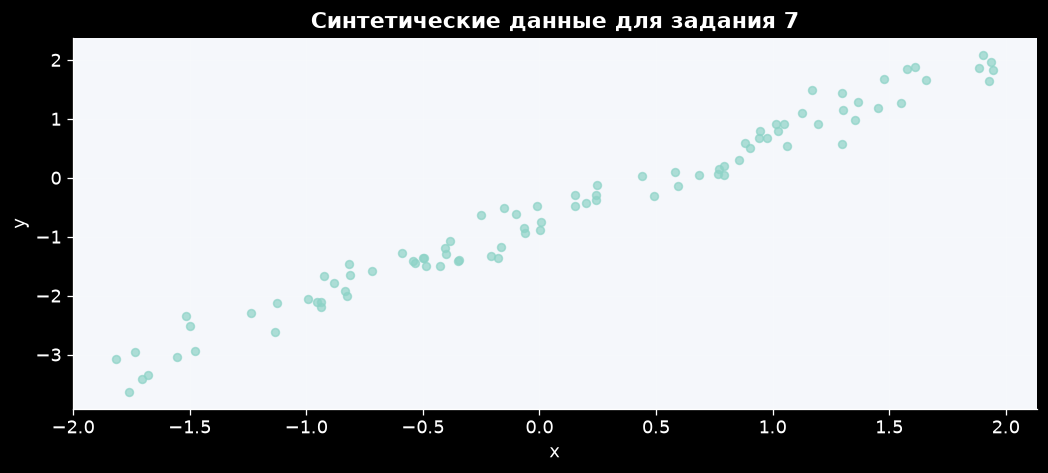

In [12]:
B_design = np.column_stack([np.array([-2., 0., 1., 3.]), np.ones(4)])
B_target = np.array([-3., 1., 3., 7.])
B_theta = np.array([0.5, -0.5])
learning_rng = np.random.default_rng(104)
learning_x = learning_rng.uniform(-2, 2, 90)
learning_design = np.column_stack([learning_x, np.ones(90)])
learning_target = 1.4 * learning_x - 0.7 + learning_rng.normal(0, 0.25, 90)
fig, ax = plt.subplots()
ax.scatter(learning_x, learning_target, s=24, alpha=0.7)
ax.set(title="Синтетические данные для задания 7", xlabel="x", ylabel="y")
plt.show()

## 5. Потеря и её градиент — 8 баллов

Реализуйте `loss_and_gradient(design, target, theta)`, возвращающую `(loss, gradient)`.
`loss` — скаляр, `gradient` имеет ту же форму, что и `theta`. Используйте векторные
операции. Формула потери:

$$L(\theta)=\frac1n\sum_i((X\theta)_i-y_i)^2.$$

**Объясните:** запишите формулу градиента, размеры её множителей и происхождение
коэффициента перед произведением. Чему равны потеря и две производные на данных
`B_design`, `B_target`, `B_theta`? Сначала разберите хотя бы одну строку вручную.
Ссылка: пособие 2, разделы 9 и 12–14.

**Ваше объяснение:** _$$ \nabla_\theta L=\frac{2}{n}X^\top(X\theta-y). $$_

In [13]:
def loss_and_gradient(design, target, theta):
    n = design.shape[0]
    loss = np.sum((design @ theta - target) ** 2) / n
    grad = 2 * design.T @ (design @ theta - target) / n
    return loss, grad

### Самопроверка задания 5

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

In [14]:
def check_gradient(value):
    loss, gradient = value
    assert np.ndim(loss) == 0 and gradient.shape == B_theta.shape
    np.testing.assert_allclose(loss, 12.375)
    np.testing.assert_allclose(gradient, [-12., -4.5])
    perfect = loss_and_gradient(B_design, B_target, np.array([2., 1.]))
    np.testing.assert_allclose(perfect[0], 0, atol=1e-12)
    np.testing.assert_allclose(perfect[1], 0, atol=1e-12)
    repeated = loss_and_gradient(np.tile(B_design, (3, 1)), np.tile(B_target, 3), B_theta)
    np.testing.assert_allclose(repeated[0], loss)
    np.testing.assert_allclose(repeated[1], gradient)

verify(5, lambda: loss_and_gradient(B_design, B_target, B_theta), check_gradient)

,Статус,Примечание
Задание,,
5,Проверки пройдены,Письменное объяснение оценивается отдельно


## 6. Независимая численная проверка — 8 баллов

Напишите `numerical_gradient(function, theta, h=1e-5)`: она возвращает центральные
конечные разности по каждой координате. Допустим цикл по координатам параметров.
Исходный `theta` должен остаться неизменным.

$$g_j\approx\frac{L(\theta+he_j)-L(\theta-he_j)}{2h}.$$

**Объясните:** почему нельзя проверять градиент только в точке минимума и почему
уменьшение `h` до $10^{-16}$ не гарантирует улучшения? После запуска сопоставьте
численную производную с заданием 5. Ссылка: пособие 2, разделы 7 и 14.

**Ваше объяснение:** _В точке минимума все сведется к тому, что мы будем сравнивать 0 с 0. Из-за ошибок округления._

In [15]:
def numerical_gradient(function, theta, h=1e-5):
    s = theta.shape
    ans = np.zeros(s, dtype='float32')
    for i in range(s[0]):
        zero = np.zeros(s, dtype='float32')
        zero[i] = 1
        grad = (function(theta + zero * h) - function(theta - zero * h)) / (2 * h)
        ans += zero * grad
    return ans

### Самопроверка задания 6

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

In [16]:
def regression_loss(theta):
    return np.mean((B_design @ theta - B_target)**2)

def check_numerical(value):
    np.testing.assert_allclose(value, [-12., -4.5], rtol=1e-6, atol=1e-7)
    point = np.array([0.7, -0.3, 1.2])
    before = point.copy()
    calculated = numerical_gradient(lambda v: np.sin(v[0]) + v[1]**2 + 3*v[2], point)
    np.testing.assert_allclose(calculated, [np.cos(0.7), -0.6, 3], atol=1e-7)
    np.testing.assert_array_equal(point, before)

display(verify(6, lambda: numerical_gradient(regression_loss, B_theta), check_numerical))
if checks[6]["Статус"] == "Проверки пройдены":
    display(pd.DataFrame({"Численный градиент": numerical_gradient(regression_loss, B_theta)}, index=["w", "b"]))

,Статус,Примечание
Задание,,
6,Проверки пройдены,Письменное объяснение оценивается отдельно


,Численный градиент
w,-12.0
b,-4.5


## 7. Обучение и чтение кривой потери — 10 баллов

Реализуйте градиентный спуск для линейной модели. Начните с нулевого вектора параметров.
Верните `(theta, history)`, где `history` содержит потерю до первого обновления и после
каждого шага, всего `steps + 1` значений. Можно использовать свою функцию из задания 5.
Не заменяйте обучение вызовом готового решателя.

Параметры контрольного запуска: `lr=0.1`, `steps=160`. График строит ячейка самопроверки.
**Объясните:** как изменилась потеря, почему она не обязана стать нулевой и доказывает ли
её снижение хорошее качество на новых данных? Ссылка: пособие 2, разделы 10 и 15–16.

**Ваше объяснение:** _Замените этот текст своим ответом._

In [17]:
def fit_linear(design, target, lr=0.1, steps=160):
    theta = np.zeros(design.shape[1], dtype='float32')
    history = []
    for step in range(steps):
        loss, grad = loss_and_gradient(design, target, theta)
        history.append(loss)
        theta -= lr * grad
    loss, _ = loss_and_gradient(design, target, theta)
    history.append(loss)

    return (theta, history)

### Самопроверка задания 7

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

,Статус,Примечание
Задание,,
7,Проверки пройдены,Письменное объяснение оценивается отдельно


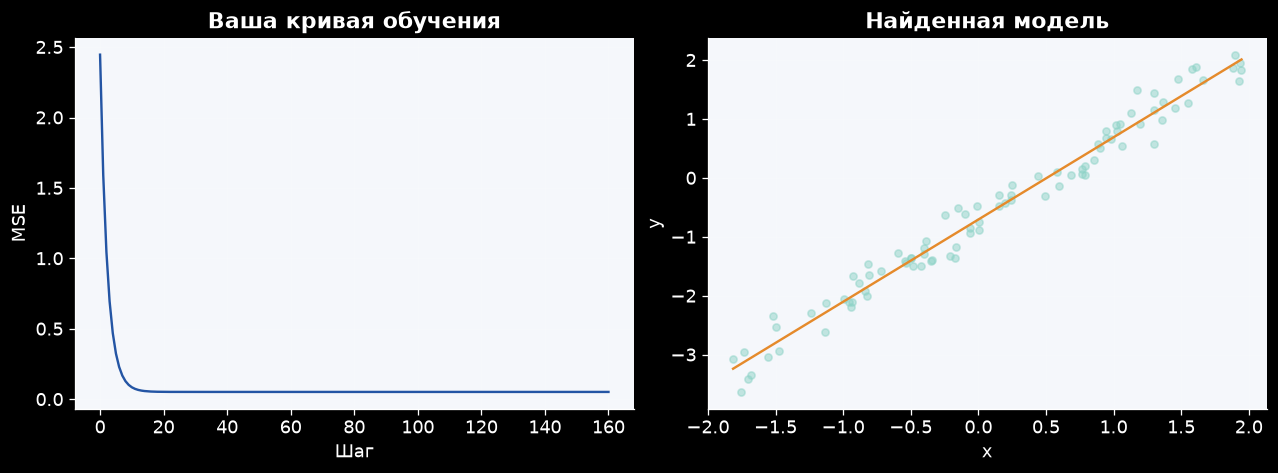

In [18]:
def check_training(value):
    theta, history = value
    history = np.asarray(history)
    assert theta.shape == (2,) and history.shape == (161,)
    assert np.isfinite(history).all() and np.isfinite(theta).all()
    np.testing.assert_allclose(history[0], np.mean(learning_target**2))
    np.testing.assert_allclose(history[-1], np.mean((learning_design @ theta - learning_target)**2))
    optimum = np.linalg.lstsq(learning_design, learning_target, rcond=None)[0]
    np.testing.assert_allclose(theta, optimum, atol=1e-5)
    assert history[-1] < history[0] * 0.1, "Потеря должна существенно уменьшиться"
    zero_theta, zero_history = fit_linear(learning_design, learning_target, steps=0)
    np.testing.assert_array_equal(zero_theta, np.zeros(2))
    assert len(zero_history) == 1, "Проверьте историю при нуле обновлений"
    other_theta, _ = fit_linear(B_design, B_target, lr=0.05, steps=250)
    np.testing.assert_allclose(other_theta, [2., 1.], atol=1e-5)

display(verify(7, lambda: fit_linear(learning_design, learning_target), check_training))
if checks[7]["Статус"] == "Проверки пройдены":
    fitted_theta, learning_history = fit_linear(learning_design, learning_target)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(learning_history, color=COLORS[0])
    axes[0].set(title="Ваша кривая обучения", xlabel="Шаг", ylabel="MSE")
    axes[1].scatter(learning_x, learning_target, alpha=0.5, s=20)
    order = np.argsort(learning_x)
    axes[1].plot(learning_x[order], (learning_design @ fitted_theta)[order], color=COLORS[1])
    axes[1].set(title="Найденная модель", xlabel="x", ylabel="y")
    plt.show()

## 8. Тот же градиент через autograd — 8 баллов

Реализуйте `torch_gradient`: переведите входы в тензоры `float64`, включите градиент
для параметров, вычислите ту же MSE и вызовите `backward`. Верните градиент как
независимый NumPy-массив. Ручную формулу производной в этой функции использовать нельзя.

**Объясните:** что произойдёт с `.grad`, если дважды вычислить потерю и вызвать
`backward` на том же тензоре параметров без сброса градиента? Чем `detach` отличается
от копирования данных? Ссылка: пособие 2, разделы 26–27.

**Ваше объяснение:** _Градиенты будут копиться (складываться друг с другом). detach() отрезает от графа вычислений, но не копирует память. А копирование clone() не отрезает от графа, но создает копию._

In [19]:
def torch_gradient(design, target, theta):
    n = design.shape[0]
    design_t = torch.tensor(design)
    target_t = torch.tensor(target)
    theta_t = torch.tensor(theta, requires_grad=True, dtype=torch.float64)
    loss = torch.sum((design_t @ theta_t - target_t) ** 2) / n
    loss.backward()
    return theta_t.grad.numpy().copy()



In [20]:
torch_gradient(B_design, B_target, B_theta)

array([-12. ,  -4.5])

### Самопроверка задания 8

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

In [21]:
def check_autograd(value):
    assert isinstance(value, np.ndarray) and value.shape == B_theta.shape
    np.testing.assert_allclose(value, [-12., -4.5], atol=1e-10)
    new_theta = np.array([-0.2, 0.8])
    before = new_theta.copy()
    another = torch_gradient(B_design, B_target, new_theta)
    expected = 2 * B_design.T @ (B_design @ new_theta - B_target) / len(B_target)
    np.testing.assert_allclose(another, expected, atol=1e-10)
    np.testing.assert_array_equal(new_theta, before)
    np.testing.assert_allclose(torch_gradient(B_design, B_target, B_theta), value, atol=1e-10)

verify(8, lambda: torch_gradient(B_design, B_target, B_theta), check_autograd)

,Статус,Примечание
Задание,,
8,Проверки пройдены,Письменное объяснение оценивается отдельно


## Данные для блока C: честный эксперимент

Данные синтетические: восемь числовых признаков и бинарная цель. Около четверти
наблюдений положительные. В признаки добавлены случайные пропуски.
`C_train` используется для обучения, `C_validation` — для учебной оценки.
Независимый test здесь намеренно не выдаётся: не называйте validation финальным тестом.

[Пособие 3](../03_honest_ml_experiment.ipynb), разделы 2–12, 18–24.
В задании 11 будет отдельный маленький набор вероятностей, чтобы выбор порога можно
было проверить независимо от выполнения задания 10.

In [22]:
all_X, all_y = make_classification(n_samples=480, n_features=8, n_informative=5,
                                  n_redundant=1, weights=[0.75, 0.25], class_sep=1.2, random_state=31)
C_train, C_validation, c_y_train, c_y_validation = train_test_split(
    all_X, all_y, test_size=0.25, stratify=all_y, random_state=42)
missing_rng = np.random.default_rng(52)
C_train[missing_rng.random(C_train.shape) < 0.04] = np.nan
C_validation[missing_rng.random(C_validation.shape) < 0.04] = np.nan
C_train_snapshot, C_validation_snapshot = C_train.copy(), C_validation.copy()
pd.DataFrame({"Объектов": [len(C_train), len(C_validation)],
              "Доля положительных": [c_y_train.mean(), c_y_validation.mean()],
              "Доля пропусков": [np.isnan(C_train).mean(), np.isnan(C_validation).mean()]},
             index=["Train", "Validation"])

,Объектов,Доля положительных,Доля пропусков
Train,360,0.25556,0.03750
Validation,120,0.25000,0.03438


## 9. Выбираем способ разделения — 8 баллов

Укажите для каждого сценария одно значение: `random`, `group` или `time`.

| Ключ | Сценарий |
| --- | --- |
| `independent` | Независимые объекты из одного стабильного распределения; один объект — одна строка |
| `new_devices` | По 20 записей с каждого устройства; после запуска будут совершенно новые устройства |
| `future` | Почасовые наблюдения; нужно прогнозировать следующие сутки по прошлой истории |

**Объясните:** чем будет ошибочно случайное разделение строк во втором и третьем
сценариях? Для временного сценария также укажите, когда нужен зазор между выборками.
Ссылка: пособие 3, разделы 2 и 20–21.

**Ваше объяснение:** _В случае future мы при обучении будем заглядывать в будущее (утечка данных). А при new_devices при случайном разделении часть записей устройства попадёт в train, а часть в test. Модель узнает устройство по его особенностям, и оценка будет завышена. Нужно использовать зазор в случае, когда, например, мы используем скользящее окно (чтобы мы могли формировать эти признаки)._

In [23]:
split_choices = {"independent": 'random', "new_devices": 'group', "future": 'time'}

### Самопроверка задания 9

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

In [24]:
def check_splits(value):
    assert set(value) == {"independent", "new_devices", "future"}
    assert value["independent"] == "random", "Учитывайте независимость объектов"
    assert value["new_devices"] == "group", "Контроль должен содержать новые устройства"
    assert value["future"] == "time", "Обучение должно предшествовать прогнозируемому периоду"

verify(9, lambda: split_choices, check_splits)

,Статус,Примечание
Задание,,
9,Проверки пройдены,Письменное объяснение оценивается отдельно


## 10. Предобработка внутри Pipeline — 8 баллов

Соберите и обучите функцию `fit_classifier(train, target)`, возвращающую `Pipeline`:
`imputer` — `SimpleImputer(strategy="median")`, `scaler` — `StandardScaler`,
`model` — `LogisticRegression(C=1.0, max_iter=2000)`. Статистики должны вычисляться
только по переданному train. Не используйте внутри функции глобальные `C_validation`
и контрольные метки. Исходные данные не изменяйте.

Самопроверка выведет вероятности и метрики на validation; минимального порога качества
в этом задании нет. Проверяется корректность процедуры.

**Объясните:** что запоминают imputer и scaler, почему `fit_transform` на всех данных
до разделения является утечкой и гарантирует ли Pipeline отсутствие любых утечек?
Ссылка: пособие 3, разделы 5–6 и 18–19.

**Ваше объяснение:** _imputer запоминает, какими значениями надо заполнять пропуски в признаках, scaler запоминает, как надо отнормировать данные. Потому что мы не должны обучаться на валидационных данных, в том числе и импутеры, и скейлеры. Да, насколько я знаю, гарантирует._

In [25]:
def fit_classifier(train, target):
    pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(C=1.0, max_iter=2000))
    ])
    pipeline.fit(train, target)
    return pipeline

### Самопроверка задания 10

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

,Статус,Примечание
Задание,,
10,Проверки пройдены,Письменное объяснение оценивается отдельно


,Precision,Recall,F1
"Validation, t=0.5",0.74194,0.76667,0.7541


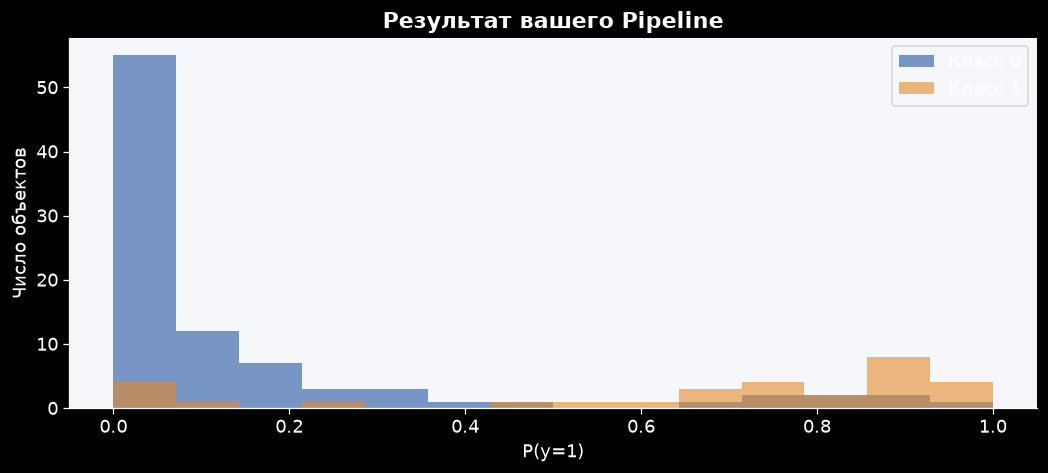

In [26]:
def check_pipeline(value):
    assert isinstance(value, Pipeline), "Верните обученный Pipeline"
    assert list(value.named_steps) == ["imputer", "scaler", "model"]
    assert isinstance(value.named_steps["imputer"], SimpleImputer)
    assert value.named_steps["imputer"].strategy == "median"
    assert isinstance(value.named_steps["scaler"], StandardScaler)
    assert isinstance(value.named_steps["model"], LogisticRegression)
    assert value.named_steps["model"].C == 1.0
    np.testing.assert_allclose(value.named_steps["imputer"].statistics_, np.nanmedian(C_train_snapshot, axis=0))
    filled = value.named_steps["imputer"].transform(C_train_snapshot)
    np.testing.assert_allclose(value.named_steps["scaler"].mean_, filled.mean(axis=0))
    probability = value.predict_proba(C_validation)
    assert probability.shape == (len(C_validation), 2) and np.isfinite(probability).all()
    np.testing.assert_allclose(probability.sum(axis=1), 1)
    np.testing.assert_array_equal(C_train, C_train_snapshot)
    np.testing.assert_array_equal(C_validation, C_validation_snapshot)
    shifted_train = C_train_snapshot + 10
    shifted_model = fit_classifier(shifted_train, c_y_train)
    np.testing.assert_allclose(shifted_model.named_steps["imputer"].statistics_, np.nanmedian(shifted_train, axis=0))

display(verify(10, lambda: fit_classifier(C_train, c_y_train), check_pipeline))
if checks[10]["Статус"] == "Проверки пройдены":
    classifier = fit_classifier(C_train, c_y_train)
    probability = classifier.predict_proba(C_validation)[:, 1]
    predictions = probability >= 0.5
    display(pd.DataFrame({"Precision": [precision_score(c_y_validation, predictions, zero_division=0)],
                          "Recall": [recall_score(c_y_validation, predictions, zero_division=0)],
                          "F1": [f1_score(c_y_validation, predictions, zero_division=0)]}, index=["Validation, t=0.5"]))
    fig, ax = plt.subplots()
    for label, color in [(0, COLORS[0]), (1, COLORS[1])]:
        ax.hist(probability[c_y_validation == label], bins=np.linspace(0, 1, 15),
                alpha=0.6, color=color, label=f"Класс {label}")
    ax.set(title="Результат вашего Pipeline", xlabel="P(y=1)", ylabel="Число объектов")
    ax.legend()
    plt.show()

## 11. Выбор порога по F1 — 8 баллов

Реализуйте `choose_threshold(target, probability, thresholds)`. Для каждого порога
считайте предсказание как `probability >= threshold`, оцените F1 с `zero_division=0`
и верните `(best_threshold, scores)`. `scores` должен иметь ту же длину и порядок,
что и входная сетка. При равных максимумах выбирайте **наименьший порог**, даже если
сетка подана в другом порядке.

$$F_1=\frac{2TP}{2TP+FP+FN}.$$

**Объясните:** почему 0.5 не обязан быть лучшим порогом и почему нельзя выбрать
порог по test, а затем сообщить ту же test-метрику как независимую? Укажите,
какой порог выбрал ваш код. Ссылка: пособие 3, разделы 9–12 и 15.

**Ваше объяснение:** _Замените этот текст своим ответом._

In [27]:
threshold_y = np.array([0, 0, 0, 0, 1, 1, 1, 1])
threshold_p = np.array([0.10, 0.20, 0.40, 0.60, 0.35, 0.55, 0.75, 0.90])
threshold_grid = np.array([0.25, 0.35, 0.50, 0.65, 0.80])

def choose_threshold(target, probability, thresholds):
    return None

### Самопроверка задания 11

Проверки ниже проверяют численный результат и основные граничные случаи. Не изменяйте их.

In [28]:
def check_threshold(value):
    threshold, scores = value
    scores = np.asarray(scores)
    assert scores.shape == threshold_grid.shape
    np.testing.assert_allclose(scores, [0.8, 0.8, 0.75, 2/3, 0.4])
    np.testing.assert_allclose(threshold, 0.25)
    reverse_threshold, reverse_scores = choose_threshold(threshold_y, threshold_p, threshold_grid[::-1])
    np.testing.assert_allclose(reverse_threshold, threshold)
    np.testing.assert_allclose(reverse_scores, scores[::-1])
    edge = choose_threshold(np.array([0, 1]), np.array([0.1, 0.2]), np.array([0.9]))
    np.testing.assert_allclose(edge[1], [0.])

display(verify(11, lambda: choose_threshold(threshold_y, threshold_p, threshold_grid), check_threshold))
if checks[11]["Статус"] == "Проверки пройдены":
    selected_threshold, scores = choose_threshold(threshold_y, threshold_p, threshold_grid)
    fig, ax = plt.subplots()
    ax.plot(threshold_grid, scores, "o-", color=COLORS[0])
    ax.axvline(selected_threshold, color=COLORS[1], linestyle="--", label=f"Выбран t={selected_threshold:.2f}")
    ax.set(title="Ваш выбор рабочего порога", xlabel="Порог", ylabel="F1", ylim=(0, 1))
    ax.legend()
    plt.show()

,Статус,Примечание
Задание,,
11,Не выполнено,Замените None своим решением


## 12. Аудит чужого эксперимента — 8 баллов

Команда предсказывает класс записи датчика. От одного устройства есть много записей,
а после запуска нужно работать **на новых устройствах**. Эксперимент выглядит так:

```python
X_scaled = StandardScaler().fit_transform(X)
X_selected = SelectKBest(k=20).fit_transform(X_scaled, y)
train, test = train_test_split(np.arange(len(y)), random_state=42)
model.fit(X_selected[train], y[train])
p_test = model.predict_proba(X_selected[test])[:, 1]
threshold = best_threshold_by_f1(y[test], p_test)
reported_f1 = f1_score(y[test], p_test >= threshold)
```

Этот фрагмент приводится только для анализа, исполнять его не нужно.
Для четырёх ключей ниже поставьте `True`, если соответствующий шаг требует исправления,
и `False`, если он корректен в описанном сценарии.

**Объясните отдельно для каждого ключа:** где утечка или несоответствие будущему применению
и как исправить порядок действий. В конце предложите корректный протокол целиком
в 4–6 коротких шагах. Ссылка: пособие 3, разделы 15 и 18–21.

**Ваше объяснение:** _Замените этот текст своим ответом._

In [29]:
audit = {"scale_before_split": None, "select_before_split": None,
         "random_rows_for_new_devices": None, "threshold_on_test": None}

### Самопроверка задания 12

Автопроверка проверяет только четыре отметки. Баллы за аудит требуют ваших объяснений и исправленного протокола; одни флаги не подтверждают понимание.

In [30]:
def check_audit(value):
    required = {"scale_before_split", "select_before_split", "random_rows_for_new_devices", "threshold_on_test"}
    assert set(value) == required
    assert all(isinstance(flag, bool) for flag in value.values()), "Используйте True или False"
    assert all(value.values()), "Проверьте все этапы относительно будущего применения"

verify(12, lambda: audit, check_audit)

,Статус,Примечание
Задание,,
12,Не выполнено,Замените None своим решением


## Перед отправкой

Заполните короткую рефлексию:

- **Что пришлось перечитать и почему:** _В целом вроде бы не пришлось ничего перечитывать_.
- **Одна найденная и исправленная ошибка в своём коде:** _Забыл в 4 задание в ответе в distancies передать шаблок indices_.
- **Какая помощь использовалась:** _Пришлось только несколько раз посмотреть (спрашивал у нейронки) для некоторых методов, возващают ли они новый массив, или шарится та же самая память._.
- **Что пока осталось непонятным:** _вопросов нет_.

Последняя таблица — статус видимых кодовых проверок, **не оценка за домашнюю работу**.
Даже если все строки зелёные по смыслу, преподаватель проверит письменные ответы,
отсутствие подставленных констант и понимание решений.

Проверьте имя файла, выполните Restart Kernel → Run All и сохраните выводы.
Незаполненный шаблон не считается выполненным ДЗ.

In [31]:
expected_tasks = range(1, 13)
final_status = pd.DataFrame([
    checks.get(number, {"Задание": number, "Статус": "Проверка не запускалась", "Примечание": "Выполните все ячейки сверху вниз"})
    for number in expected_tasks
]).set_index("Задание")
final_status

,Статус,Примечание
Задание,,
1,Проверки пройдены,Письменное объяснение оценивается отдельно
2,Проверки пройдены,Письменное объяснение оценивается отдельно
3,Проверки пройдены,Письменное объяснение оценивается отдельно
4,Проверки пройдены,Письменное объяснение оценивается отдельно
5,Проверки пройдены,Письменное объяснение оценивается отдельно
6,Проверки пройдены,Письменное объяснение оценивается отдельно
7,Проверки пройдены,Письменное объяснение оценивается отдельно
8,Проверки пройдены,Письменное объяснение оценивается отдельно
9,Проверки пройдены,Письменное объяснение оценивается отдельно
